<a href="https://colab.research.google.com/github/suhrudsharma/STP-Performance-Analysis/blob/main/notebooks/STP_DataAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Spanning Tree Protocol (STP) Performance Analysis

## Notebook 1: Experimental Data Analysis

### Objective
Analyze experimental measurements collected from STP network topologies and link-failure scenarios.

### Tasks
1. Import experimental data from CSV files.
2. Validate and clean the data.
3. Calculate packet loss and convergence metrics.
4. Summarize results by topology and failure scenario.
5. Compare experimental performance across topologies.
6. Export cleaned data and summary tables for visualization and reporting.

### Data integrity
All experimental measurements must originate from actual network experiments. Missing measurements must not be fabricated. Calculated values must be distinguishable from raw measurements.

### Team
Swetha, Suhrud, and Isha


In [ ]:

# Cell 1: Import libraries and verify the environment

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("STP Performance Analysis")
print("------------------------")
print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)

# Create output folders in the current Colab session
os.makedirs("data/processed", exist_ok=True)
os.makedirs("results/tables", exist_ok=True)
os.makedirs("results/graphs", exist_ok=True)

print("\nRequired libraries imported successfully.")
print("Output folders created successfully.")


STP Performance Analysis
------------------------
Python version: 3.13.18
Pandas version: 2.2.3
NumPy version: 2.1.3
Matplotlib version: 3.10.0

Required libraries imported successfully.
Output folders created successfully.



## 2. Experimental Dataset Schema

This section defines the common data format used by the STP experiments.

Each row represents one experimental trial for a particular network topology and failure scenario.

Raw observations will be supplied by the network-emulation experiments. Derived metrics, such as packet-loss percentage and summary statistics, will be calculated programmatically.

Missing experimental values must remain missing rather than being replaced with invented measurements.


In [ ]:

# Cell 2: Define the shared experimental data schema

REQUIRED_COLUMNS = [
    "experiment_id",
    "topology",
    "trial_number",
    "switch_count",
    "failed_link",
    "root_bridge",
    "blocked_ports",
    "forwarding_ports",
    "path_cost",
    "packets_sent",
    "packets_received",
    "packets_lost",
    "convergence_time_ms",
    "downtime_ms",
    "bpdu_count",
    "data_source",
    "notes",
]

NUMERIC_COLUMNS = [
    "trial_number",
    "switch_count",
    "blocked_ports",
    "forwarding_ports",
    "path_cost",
    "packets_sent",
    "packets_received",
    "packets_lost",
    "convergence_time_ms",
    "downtime_ms",
    "bpdu_count",
]

print("Dataset schema defined successfully.")
print("Total columns:", len(REQUIRED_COLUMNS))
print("\nColumns:")
for column in REQUIRED_COLUMNS:
    print("-", column)


Dataset schema defined successfully.
Total columns: 17

Columns:
- experiment_id
- topology
- trial_number
- switch_count
- failed_link
- root_bridge
- blocked_ports
- forwarding_ports
- path_cost
- packets_sent
- packets_received
- packets_lost
- convergence_time_ms
- downtime_ms
- bpdu_count
- data_source
- notes



## 3. Load Experimental Data

This section provides a reusable function for loading STP experimental data from a CSV file.

The function checks whether the expected columns are present. Actual experimental measurements will be loaded when the network experiments are completed.


In [ ]:

# Cell 3: Reusable CSV loader

from pathlib import Path

def load_stp_data(file_path):
    """
    Load an STP experimental dataset from CSV.

    Parameters
    ----------
    file_path : str or Path
        Path to the CSV file.

    Returns
    -------
    pandas.DataFrame
        Loaded dataset after basic schema validation.
    """
    file_path = Path(file_path)

    if not file_path.exists():
        raise FileNotFoundError(
            f"CSV file not found: {file_path}\n"
            "Check the path or upload the experimental CSV."
        )

    df = pd.read_csv(file_path)

    missing_columns = [
        col for col in REQUIRED_COLUMNS
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            "The CSV is missing required columns: "
            + ", ".join(missing_columns)
        )

    print("CSV loaded successfully.")
    print("Rows:", len(df))
    print("Columns:", len(df.columns))

    return df


print("STP CSV loader defined successfully.")
print("Expected columns:", len(REQUIRED_COLUMNS))


STP CSV loader defined successfully.
Expected columns: 17



## 4. Data Validation and Cleaning

This section checks the integrity of the STP experimental dataset.

It identifies missing columns, duplicate experiments, invalid numeric values, inconsistent packet counts, and missing measurements. Raw measurements are preserved; invalid or missing values are not silently replaced with invented values.


In [ ]:

# Cell 4: Data validation and cleaning functions

def validate_stp_data(df):
    """Validate an STP dataset without inventing missing measurements."""

    report = {
        "row_count": len(df),
        "column_count": len(df.columns),
        "missing_values": df.isna().sum(),
        "duplicate_rows": int(df.duplicated().sum()),
        "invalid_numeric_values": {},
        "invalid_packet_counts": 0,
        "negative_metrics": {},
    }

    for col in NUMERIC_COLUMNS:
        if col in df.columns:
            converted = pd.to_numeric(df[col], errors="coerce")
            report["invalid_numeric_values"][col] = int(
                (df[col].notna() & converted.isna()).sum()
            )

            report["negative_metrics"][col] = int(
                (converted < 0).sum()
            )

    if {"packets_sent", "packets_received"}.issubset(df.columns):
        sent = pd.to_numeric(df["packets_sent"], errors="coerce")
        received = pd.to_numeric(df["packets_received"], errors="coerce")

        invalid = (
            (sent < 0)
            | (received < 0)
            | (received > sent)
        )
        report["invalid_packet_counts"] = int(invalid.sum())

    print("DATA VALIDATION REPORT")
    print("=" * 40)
    print("Rows:", report["row_count"])
    print("Columns:", report["column_count"])
    print("Duplicate rows:", report["duplicate_rows"])

    print("\nMissing values by column:")
    display(report["missing_values"].to_frame("missing_count"))

    print("\nInvalid numeric entries:")
    display(pd.Series(report["invalid_numeric_values"], name="count").to_frame())

    print("\nNegative values by numeric column:")
    display(pd.Series(report["negative_metrics"], name="count").to_frame())

    print("\nRows with inconsistent packet counts:",
          report["invalid_packet_counts"])

    return report


def clean_stp_data(df):
    """
    Create a cleaned copy with numeric columns converted to numeric types.
    Does not impute missing values or delete experimental observations.
    """
    cleaned = df.copy()

    for col in NUMERIC_COLUMNS:
        if col in cleaned.columns:
            cleaned[col] = pd.to_numeric(cleaned[col], errors="coerce")

    return cleaned


print("Validation and cleaning functions defined successfully.")


Validation and cleaning functions defined successfully.



## 5. Performance Metric Calculations

This section calculates derived performance metrics from recorded experimental measurements.

Packet-loss percentage is calculated from packets sent and received. Convergence-time and downtime measurements remain separate. Missing raw measurements remain missing.


In [ ]:

# Cell 5: Calculate derived metrics

def calculate_stp_metrics(df):
    """Return a copy of the dataset with derived metrics."""

    result = clean_stp_data(df)

    # Calculate packets lost only when sent and received are both available.
    if {"packets_sent", "packets_received"}.issubset(result.columns):
        sent = result["packets_sent"]
        received = result["packets_received"]

        valid_counts = (
            sent.notna()
            & received.notna()
            & (sent >= 0)
            & (received >= 0)
            & (received <= sent)
        )

        result["calculated_packets_lost"] = (
            sent - received
        ).where(valid_counts)

        # If packets_lost was independently recorded, preserve it.
        # Use the calculated value only in the derived column above.
        result["packet_loss_percent"] = (
            100 * (sent - received) / sent
        ).where(valid_counts & (sent > 0))

    # Create explicit units and names for downstream analysis.
    if "convergence_time_ms" in result.columns:
        result["convergence_time_s"] = (
            result["convergence_time_ms"] / 1000
        )

    if "downtime_ms" in result.columns:
        result["downtime_s"] = result["downtime_ms"] / 1000

    return result


print("Performance metric calculation function defined successfully.")


Performance metric calculation function defined successfully.



## 6. Summary Statistics by Topology

Summarize actual experimental measurements by topology. Mean and median convergence time are calculated only from available valid measurements. The number of valid observations is reported alongside each statistic.


In [ ]:

# Cell 6: Summary statistics

def summarize_by_topology(df):
    """Summarize performance measurements by topology."""

    data = calculate_stp_metrics(df)

    if "topology" not in data.columns:
        raise ValueError("Dataset must contain a topology column.")

    metric_columns = [
        "convergence_time_ms",
        "downtime_ms",
        "packet_loss_percent",
        "blocked_ports",
        "forwarding_ports",
        "bpdu_count",
        "path_cost",
    ]

    available = [c for c in metric_columns if c in data.columns]

    if not available:
        raise ValueError("No supported performance metric columns found.")

    summary = data.groupby("topology", dropna=False)[available].agg(
        ["count", "mean", "median", "min", "max"]
    )

    return summary


print("Topology summary function defined successfully.")


Topology summary function defined successfully.



## 7. Failure Scenario Comparison

Compare experimental results by topology and failed link. Each row remains associated with its original experiment and trial.


In [ ]:

# Cell 7: Failure scenario summary

def summarize_failures(df):
    """Summarize measured performance by topology and failed link."""

    data = calculate_stp_metrics(df)

    grouping = [
        c for c in ["topology", "failed_link"]
        if c in data.columns
    ]

    if not grouping:
        raise ValueError("No topology/failure columns available.")

    metrics = [
        c for c in [
            "convergence_time_ms",
            "downtime_ms",
            "packet_loss_percent",
            "blocked_ports",
            "forwarding_ports",
            "bpdu_count",
        ]
        if c in data.columns
    ]

    return data.groupby(grouping, dropna=False)[metrics].agg(
        ["count", "mean", "median"]
    )


print("Failure comparison function defined successfully.")


Failure comparison function defined successfully.



## 8. Export Processed Data and Summary Tables

Save processed data and summary tables for the visualization notebook and final report. Only actual imported experimental data should be exported as experimental results.


In [ ]:

# Cell 8: Export functions

from pathlib import Path

OUTPUT_DIR = Path("results")
TABLE_DIR = OUTPUT_DIR / "tables"
PROCESSED_DIR = Path("data") / "processed"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


def export_stp_analysis(df, prefix="stp"):
    """Export processed measurements and summary tables."""

    processed = calculate_stp_metrics(df)
    topology_summary = summarize_by_topology(df)
    failure_summary = summarize_failures(df)

    processed.to_csv(
        PROCESSED_DIR / f"{prefix}_processed.csv",
        index=False
    )

    topology_summary.to_csv(
        TABLE_DIR / f"{prefix}_topology_summary.csv"
    )

    failure_summary.to_csv(
        TABLE_DIR / f"{prefix}_failure_summary.csv"
    )

    print("Analysis exports saved:")
    print(PROCESSED_DIR / f"{prefix}_processed.csv")
    print(TABLE_DIR / f"{prefix}_topology_summary.csv")
    print(TABLE_DIR / f"{prefix}_failure_summary.csv")

    return processed, topology_summary, failure_summary


print("Export functions defined successfully.")


Export functions defined successfully.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

CSV_PATH = (
    '/content/drive/MyDrive/STP_Performance_Analysis/'
    'stp_experiment_cleaned.csv'
)

df_raw = pd.read_csv(CSV_PATH)
print(df_raw.shape)
display(df_raw.head())

Mounted at /content/drive
(7, 16)


,experiment_id,topology,switch_count,failure_link,failure_type,root_bridge,blocked_ports,forwarding_ports,path_cost,bpdu_count,convergence_time_ms,packet_loss,downtime_ms,measurement_method,notes,data_status
0,EXP_01_TRIANGLE_BASE,topology_1_triangle,3,NaN,baseline,S3,1,2,2,Not measured,Not measured,0,Not measured,measured_mininet_ovs,Initial state: Root S3. S1 root port s1-eth3 (...,Empirically Measured
1,EXP_01_TRIANGLE_FAIL,topology_1_triangle,3,S1-S3,direct,S3,1,2,4,Not measured,Not measured,0,Not measured,measured_mininet_ovs,Link S1-S3 failed. S1 root port changed s1-eth...,Empirically Measured
2,EXP_01_TRIANGLE_RECOV,topology_1_triangle,3,S1-S3,recovery,S3,1,2,2,Not measured,Not measured,0,Not measured,measured_mininet_ovs,Link S1-S3 restored. s1-eth3 observed root/lis...,Empirically Measured
3,EXP_02_MESH4_BASE,topology_2_mesh,4,NaN,baseline,S2,3,3,2,Not measured,Not measured,0,Not measured,measured_mininet_ovs,Initial state: Root S2. Blocked ports: s1-eth4...,Empirically Measured
4,EXP_02_MESH4_FAIL,topology_2_mesh,4,S1-S2,direct,S2,3,3,4,Not measured,Not measured,0,Not measured,measured_mininet_ovs,Link S1-S2 failed. S1 root port changed s1-eth...,Empirically Measured


In [ ]:

# STEP 1: Validate the STP experiment dataset

import pandas as pd

# Work on a copy so the original imported data remains unchanged
df = df_raw.copy()

# Standardize column names
df.columns = df.columns.str.strip()

# Convert placeholder text into proper missing values for analysis
df = df.replace(r'^\s*Not measured\s*$', pd.NA, regex=True)

print("Dataset shape:", df.shape)
print("\nColumn data types:")
display(df.dtypes.to_frame(name="Data type"))

print("\nMissing values in each column:")
display(df.isna().sum().to_frame(name="Missing count"))

print("\nExperiment status counts:")
display(df["data_status"].value_counts(dropna=False).to_frame(name="Count"))

print("\nDuplicate experiment IDs:", df["experiment_id"].duplicated().sum())

print("\nExperiment records:")
display(df[["experiment_id", "topology", "failure_type", "data_status"]])

# Check required identifiers and categorical fields
required_columns = [
    "experiment_id", "topology", "switch_count",
    "failure_type", "data_status"
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    print("\nERROR: Required columns missing:", missing_columns)
else:
    print("\nValidation checks completed.")


Dataset shape: (7, 16)

Column data types:


,Data type
experiment_id,object
topology,object
switch_count,int64
failure_link,object
failure_type,object
root_bridge,object
blocked_ports,int64
forwarding_ports,int64
path_cost,int64
bpdu_count,object



Missing values in each column:


,Missing count
experiment_id,0
topology,0
switch_count,0
failure_link,2
failure_type,0
root_bridge,0
blocked_ports,0
forwarding_ports,0
path_cost,0
bpdu_count,7



Experiment status counts:


,Count
data_status,
Empirically Measured,5
Planned / Reference,2



Duplicate experiment IDs: 0

Experiment records:


,experiment_id,topology,failure_type,data_status
0,EXP_01_TRIANGLE_BASE,topology_1_triangle,baseline,Empirically Measured
1,EXP_01_TRIANGLE_FAIL,topology_1_triangle,direct,Empirically Measured
2,EXP_01_TRIANGLE_RECOV,topology_1_triangle,recovery,Empirically Measured
3,EXP_02_MESH4_BASE,topology_2_mesh,baseline,Empirically Measured
4,EXP_02_MESH4_FAIL,topology_2_mesh,direct,Empirically Measured
5,EXP_03_TREE_PLANNED,topology_3_tree_redundant,planned,Planned / Reference
6,EXP_04_MESH5_PLANNED,topology_4_large_mesh,planned,Planned / Reference



Validation checks completed.


In [ ]:

# STEP 2: Identify which performance metrics are available

metric_columns = [
    "blocked_ports",
    "forwarding_ports",
    "path_cost",
    "bpdu_count",
    "convergence_time_ms",
    "packet_loss",
    "downtime_ms"
]

# Convert metrics to numeric where possible.
# Text such as "Not measured" becomes NaN.
for col in metric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

measured_df = df[
    df["data_status"].eq("Empirically Measured")
].copy()

reference_df = df[
    df["data_status"].eq("Planned / Reference")
].copy()

print("Empirically measured experiments:", len(measured_df))
print("Planned/reference experiments:", len(reference_df))

print("\nAvailable numeric measurements in empirical rows:")
display(measured_df[metric_columns].notna().sum().to_frame(
    name="Available measurements"
))

print("\nSummary of available empirical metrics:")
display(measured_df[metric_columns].describe().T)

print("\nEmpirically measured experiment details:")
display(
    measured_df[
        ["experiment_id", "topology", "failure_type"] + metric_columns
    ]
)


Empirically measured experiments: 5
Planned/reference experiments: 2

Available numeric measurements in empirical rows:


,Available measurements
blocked_ports,5
forwarding_ports,5
path_cost,5
bpdu_count,0
convergence_time_ms,0
packet_loss,5
downtime_ms,0



Summary of available empirical metrics:


,count,mean,std,min,25%,50%,75%,max
blocked_ports,5.0,1.8,1.095445,1.0,1.0,1.0,3.0,3.0
forwarding_ports,5.0,2.4,0.547723,2.0,2.0,2.0,3.0,3.0
path_cost,5.0,2.8,1.095445,2.0,2.0,2.0,4.0,4.0
bpdu_count,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
convergence_time_ms,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
packet_loss,5.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
downtime_ms,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Empirically measured experiment details:


,experiment_id,topology,failure_type,blocked_ports,forwarding_ports,path_cost,bpdu_count,convergence_time_ms,packet_loss,downtime_ms
0,EXP_01_TRIANGLE_BASE,topology_1_triangle,baseline,1,2,2,NaN,NaN,0.0,NaN
1,EXP_01_TRIANGLE_FAIL,topology_1_triangle,direct,1,2,4,NaN,NaN,0.0,NaN
2,EXP_01_TRIANGLE_RECOV,topology_1_triangle,recovery,1,2,2,NaN,NaN,0.0,NaN
3,EXP_02_MESH4_BASE,topology_2_mesh,baseline,3,3,2,NaN,NaN,0.0,NaN
4,EXP_02_MESH4_FAIL,topology_2_mesh,direct,3,3,4,NaN,NaN,0.0,NaN


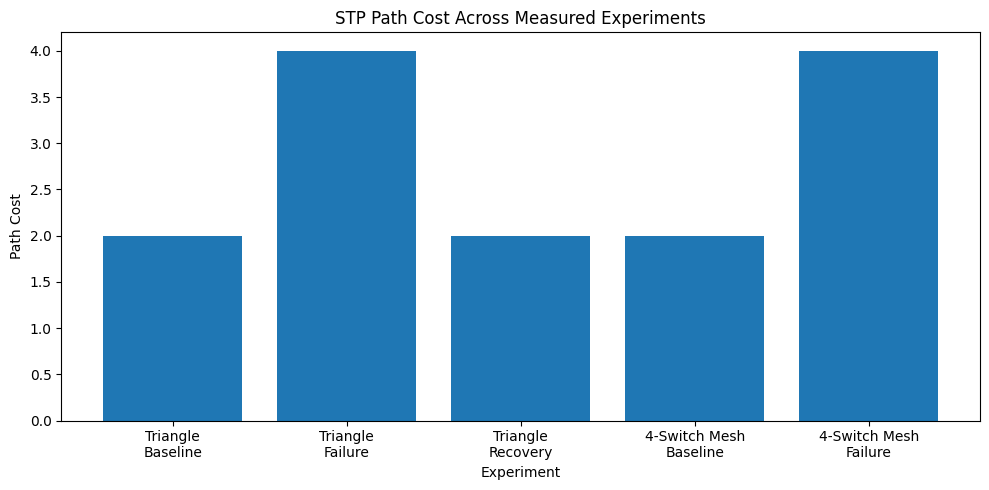

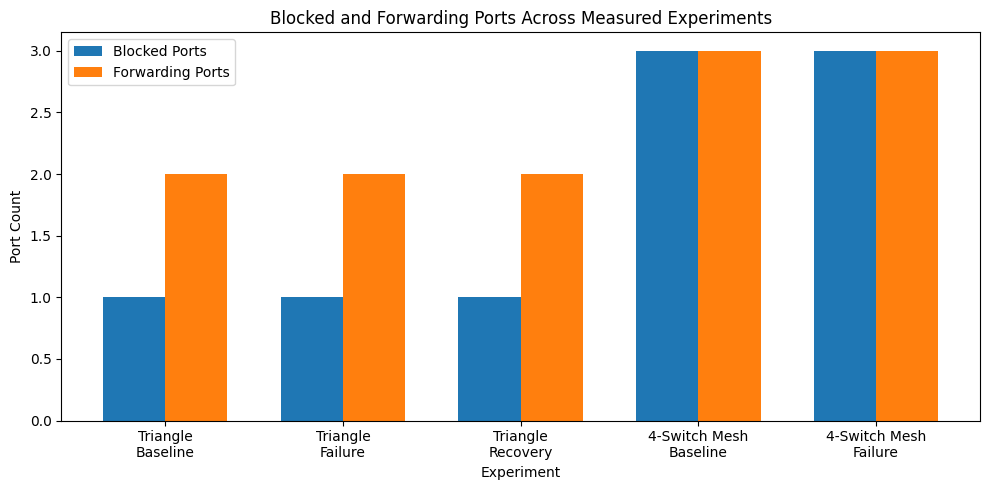

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

# Use only empirically measured experiments
plot_df = measured_df.copy()

# Short labels for readable plots
plot_df["experiment_label"] = plot_df["experiment_id"].map({
    "EXP_01_TRIANGLE_BASE": "Triangle\nBaseline",
    "EXP_01_TRIANGLE_FAIL": "Triangle\nFailure",
    "EXP_01_TRIANGLE_RECOV": "Triangle\nRecovery",
    "EXP_02_MESH4_BASE": "4-Switch Mesh\nBaseline",
    "EXP_02_MESH4_FAIL": "4-Switch Mesh\nFailure"
})

# 1. Path cost
plt.figure(figsize=(10, 5))
plt.bar(plot_df["experiment_label"], plot_df["path_cost"])
plt.title("STP Path Cost Across Measured Experiments")
plt.xlabel("Experiment")
plt.ylabel("Path Cost")
plt.tight_layout()
plt.show()

# 2. Blocked and forwarding ports
x = range(len(plot_df))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(
    [i - width / 2 for i in x],
    plot_df["blocked_ports"],
    width=width,
    label="Blocked Ports"
)
plt.bar(
    [i + width / 2 for i in x],
    plot_df["forwarding_ports"],
    width=width,
    label="Forwarding Ports"
)
plt.xticks(list(x), plot_df["experiment_label"])
plt.title("Blocked and Forwarding Ports Across Measured Experiments")
plt.xlabel("Experiment")
plt.ylabel("Port Count")
plt.legend()
plt.tight_layout()
plt.show()


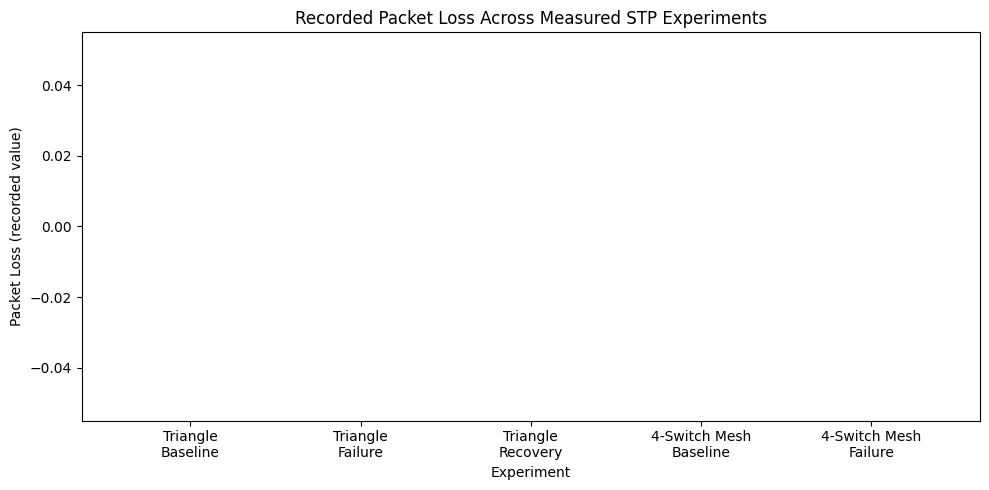

Baseline vs. link-failure comparison:


,Topology,Baseline Path Cost,Failure Path Cost,Path Cost Change,Baseline Blocked Ports,Failure Blocked Ports,Baseline Forwarding Ports,Failure Forwarding Ports,Baseline Packet Loss,Failure Packet Loss
0,Triangle,2,4,2,1,1,2,2,0.0,0.0
1,4-Switch Mesh,2,4,2,3,3,3,3,0.0,0.0


In [ ]:

# STEP 5: Packet loss analysis and baseline-vs-failure comparison
# Self-contained cell — run as is

import pandas as pd
import matplotlib.pyplot as plt

# Start from the validated dataset
analysis_df = df.copy()

# Keep only empirically measured experiments
analysis_df = analysis_df[
    analysis_df["data_status"] == "Empirically Measured"
].copy()

# Ensure numeric metric columns are numeric
for col in [
    "path_cost", "blocked_ports", "forwarding_ports", "packet_loss"
]:
    analysis_df[col] = pd.to_numeric(analysis_df[col], errors="coerce")

# Create readable labels in this cell
label_map = {
    "EXP_01_TRIANGLE_BASE": "Triangle\nBaseline",
    "EXP_01_TRIANGLE_FAIL": "Triangle\nFailure",
    "EXP_01_TRIANGLE_RECOV": "Triangle\nRecovery",
    "EXP_02_MESH4_BASE": "4-Switch Mesh\nBaseline",
    "EXP_02_MESH4_FAIL": "4-Switch Mesh\nFailure"
}

analysis_df["experiment_label"] = (
    analysis_df["experiment_id"].map(label_map)
    .fillna(analysis_df["experiment_id"])
)

# 1. Plot recorded packet loss
packet_df = analysis_df.dropna(subset=["packet_loss"])

if not packet_df.empty:
    plt.figure(figsize=(10, 5))
    plt.bar(packet_df["experiment_label"], packet_df["packet_loss"])
    plt.title("Recorded Packet Loss Across Measured STP Experiments")
    plt.xlabel("Experiment")
    plt.ylabel("Packet Loss (recorded value)")
    plt.tight_layout()
    plt.show()
else:
    print("No numeric packet-loss measurements are available.")

# 2. Compare baseline vs. link failure
experiment_ids = set(analysis_df["experiment_id"])

comparison_pairs = [
    ("Triangle", "EXP_01_TRIANGLE_BASE", "EXP_01_TRIANGLE_FAIL"),
    ("4-Switch Mesh", "EXP_02_MESH4_BASE", "EXP_02_MESH4_FAIL")
]

results = []

for topology_name, baseline_id, failure_id in comparison_pairs:
    if baseline_id not in experiment_ids or failure_id not in experiment_ids:
        print(f"Skipping {topology_name}: baseline or failure row is missing.")
        continue

    baseline = analysis_df.loc[
        analysis_df["experiment_id"] == baseline_id
    ].iloc[0]

    failure = analysis_df.loc[
        analysis_df["experiment_id"] == failure_id
    ].iloc[0]

    results.append({
        "Topology": topology_name,
        "Baseline Path Cost": baseline["path_cost"],
        "Failure Path Cost": failure["path_cost"],
        "Path Cost Change": failure["path_cost"] - baseline["path_cost"],
        "Baseline Blocked Ports": baseline["blocked_ports"],
        "Failure Blocked Ports": failure["blocked_ports"],
        "Baseline Forwarding Ports": baseline["forwarding_ports"],
        "Failure Forwarding Ports": failure["forwarding_ports"],
        "Baseline Packet Loss": baseline["packet_loss"],
        "Failure Packet Loss": failure["packet_loss"]
    })

comparison_results = pd.DataFrame(results)

print("Baseline vs. link-failure comparison:")
display(comparison_results)


In [ ]:

# STEP 6: Consolidated results table for the project report

import pandas as pd

# Use the validated dataset and only empirical measurements
report_df = df.loc[
    df["data_status"].eq("Empirically Measured")
].copy()

# Ensure numeric columns are handled consistently
numeric_columns = [
    "switch_count",
    "blocked_ports",
    "forwarding_ports",
    "path_cost",
    "packet_loss",
    "convergence_time_ms",
    "downtime_ms",
    "bpdu_count"
]

for col in numeric_columns:
    report_df[col] = pd.to_numeric(report_df[col], errors="coerce")

report_columns = [
    "experiment_id",
    "topology",
    "switch_count",
    "failure_type",
    "failure_link",
    "root_bridge",
    "blocked_ports",
    "forwarding_ports",
    "path_cost",
    "packet_loss",
    "convergence_time_ms",
    "downtime_ms",
    "bpdu_count"
]

print("Consolidated empirical results")
display(report_df[report_columns].reset_index(drop=True))

print("\nMissing performance measurements:")
missing_metrics = report_df[
    ["convergence_time_ms", "downtime_ms", "bpdu_count"]
].isna().sum().to_frame(name="Missing empirical values")

display(missing_metrics)


Consolidated empirical results


,experiment_id,topology,switch_count,failure_type,failure_link,root_bridge,blocked_ports,forwarding_ports,path_cost,packet_loss,convergence_time_ms,downtime_ms,bpdu_count
0,EXP_01_TRIANGLE_BASE,topology_1_triangle,3,baseline,NaN,S3,1,2,2,0.0,NaN,NaN,NaN
1,EXP_01_TRIANGLE_FAIL,topology_1_triangle,3,direct,S1-S3,S3,1,2,4,0.0,NaN,NaN,NaN
2,EXP_01_TRIANGLE_RECOV,topology_1_triangle,3,recovery,S1-S3,S3,1,2,2,0.0,NaN,NaN,NaN
3,EXP_02_MESH4_BASE,topology_2_mesh,4,baseline,NaN,S2,3,3,2,0.0,NaN,NaN,NaN
4,EXP_02_MESH4_FAIL,topology_2_mesh,4,direct,S1-S2,S2,3,3,4,0.0,NaN,NaN,NaN



Missing performance measurements:


,Missing empirical values
convergence_time_ms,5
downtime_ms,5
bpdu_count,5


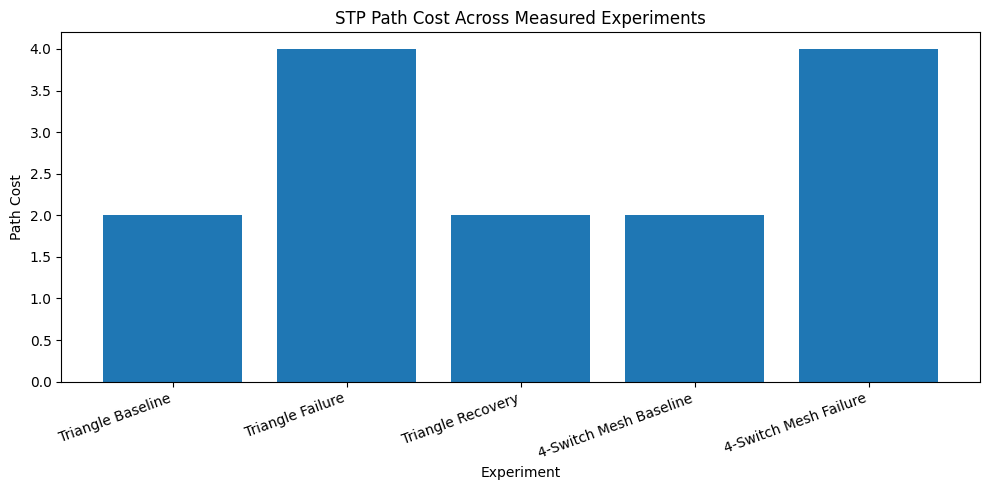

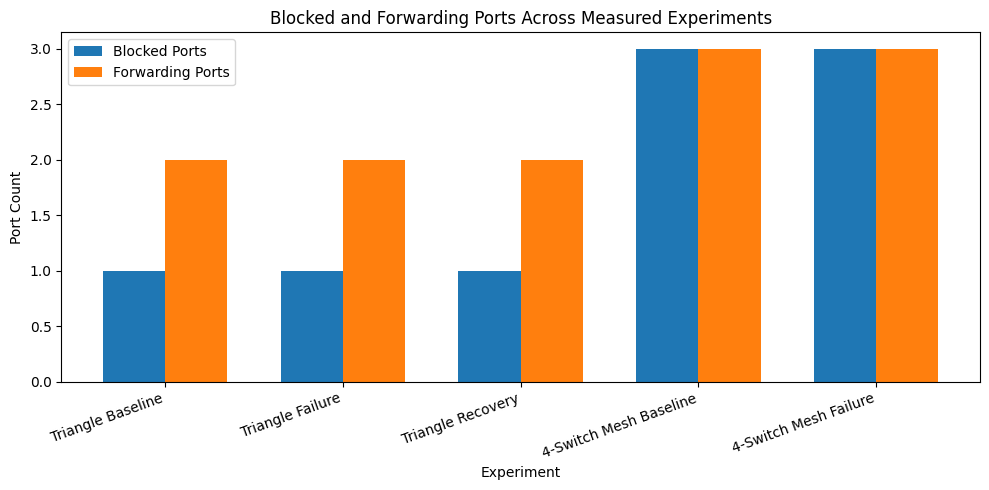

Saved files to: /content/drive/MyDrive/STP_Performance_Analysis/results

Baseline vs. failure summary:


,Topology,Baseline Path Cost,Failure Path Cost,Path Cost Change,Baseline Blocked Ports,Failure Blocked Ports,Baseline Forwarding Ports,Failure Forwarding Ports,Baseline Recorded Packet Loss,Failure Recorded Packet Loss
0,Triangle,2,4,2,1,1,2,2,0.0,0.0
1,4-Switch Mesh,2,4,2,3,3,3,3,0.0,0.0


In [ ]:

# STEP 7: Final figures and export report tables

import os
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = "/content/drive/MyDrive/STP_Performance_Analysis/results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Use measured records only
final_df = df[df["data_status"] == "Empirically Measured"].copy()

for col in ["path_cost", "blocked_ports", "forwarding_ports", "packet_loss"]:
    final_df[col] = pd.to_numeric(final_df[col], errors="coerce")

labels = {
    "EXP_01_TRIANGLE_BASE": "Triangle Baseline",
    "EXP_01_TRIANGLE_FAIL": "Triangle Failure",
    "EXP_01_TRIANGLE_RECOV": "Triangle Recovery",
    "EXP_02_MESH4_BASE": "4-Switch Mesh Baseline",
    "EXP_02_MESH4_FAIL": "4-Switch Mesh Failure"
}
final_df["label"] = final_df["experiment_id"].map(labels).fillna(final_df["experiment_id"])

# Figure 1: Path cost
plt.figure(figsize=(10, 5))
plt.bar(final_df["label"], final_df["path_cost"])
plt.title("STP Path Cost Across Measured Experiments")
plt.xlabel("Experiment")
plt.ylabel("Path Cost")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "path_cost.png"), dpi=300)
plt.show()

# Figure 2: Port counts
x = range(len(final_df))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar([i - width/2 for i in x], final_df["blocked_ports"],
        width=width, label="Blocked Ports")
plt.bar([i + width/2 for i in x], final_df["forwarding_ports"],
        width=width, label="Forwarding Ports")
plt.xticks(list(x), final_df["label"], rotation=20, ha="right")
plt.title("Blocked and Forwarding Ports Across Measured Experiments")
plt.xlabel("Experiment")
plt.ylabel("Port Count")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "port_counts.png"), dpi=300)
plt.show()

# Export measured results and a concise comparison table
final_df.to_csv(os.path.join(OUTPUT_DIR, "empirical_results.csv"), index=False)

summary_rows = []
pairs = [
    ("Triangle", "EXP_01_TRIANGLE_BASE", "EXP_01_TRIANGLE_FAIL"),
    ("4-Switch Mesh", "EXP_02_MESH4_BASE", "EXP_02_MESH4_FAIL")
]

for name, base_id, fail_id in pairs:
    base = final_df.loc[final_df["experiment_id"] == base_id].iloc[0]
    fail = final_df.loc[final_df["experiment_id"] == fail_id].iloc[0]

    summary_rows.append({
        "Topology": name,
        "Baseline Path Cost": base["path_cost"],
        "Failure Path Cost": fail["path_cost"],
        "Path Cost Change": fail["path_cost"] - base["path_cost"],
        "Baseline Blocked Ports": base["blocked_ports"],
        "Failure Blocked Ports": fail["blocked_ports"],
        "Baseline Forwarding Ports": base["forwarding_ports"],
        "Failure Forwarding Ports": fail["forwarding_ports"],
        "Baseline Recorded Packet Loss": base["packet_loss"],
        "Failure Recorded Packet Loss": fail["packet_loss"]
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(os.path.join(OUTPUT_DIR, "baseline_failure_comparison.csv"), index=False)

print("Saved files to:", OUTPUT_DIR)
print("\nBaseline vs. failure summary:")
display(summary_df)


In [ ]:

# STEP 8: Generate report-ready findings and limitations

import os
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/STP_Performance_Analysis/results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Use measured data only
results_df = df[
    df["data_status"].eq("Empirically Measured")
].copy()

for col in [
    "path_cost", "blocked_ports", "forwarding_ports",
    "packet_loss", "convergence_time_ms",
    "downtime_ms", "bpdu_count"
]:
    results_df[col] = pd.to_numeric(results_df[col], errors="coerce")

# Find baseline and failure rows for each topology
pairs = [
    ("Triangle", "EXP_01_TRIANGLE_BASE", "EXP_01_TRIANGLE_FAIL"),
    ("4-Switch Mesh", "EXP_02_MESH4_BASE", "EXP_02_MESH4_FAIL")
]

findings = []

for name, base_id, fail_id in pairs:
    base = results_df.loc[results_df["experiment_id"].eq(base_id)].iloc[0]
    fail = results_df.loc[results_df["experiment_id"].eq(fail_id)].iloc[0]

    findings.append({
        "Topology": name,
        "Baseline path cost": base["path_cost"],
        "Failure path cost": fail["path_cost"],
        "Path cost change": fail["path_cost"] - base["path_cost"],
        "Blocked ports changed": base["blocked_ports"] != fail["blocked_ports"],
        "Forwarding ports changed": base["forwarding_ports"] != fail["forwarding_ports"],
        "Recorded baseline packet loss": base["packet_loss"],
        "Recorded failure packet loss": fail["packet_loss"]
    })

findings_df = pd.DataFrame(findings)

# Check which key metrics are unavailable
missing_metrics = results_df[
    ["convergence_time_ms", "downtime_ms", "bpdu_count"]
].isna().sum()

report_text = """
STP PERFORMANCE ANALYSIS — PRELIMINARY FINDINGS

1. Path cost
In both measured topologies, recorded path cost increased from 2 at baseline
to 4 during the recorded link-failure scenario. In the triangle experiment,
the recorded path cost returned to 2 after recovery.

2. Port states
The recorded blocked-port and forwarding-port counts did not change between
baseline and failure in either topology. These counts should be checked
against the experiment logs and port-state definitions before drawing
broader conclusions.

3. Packet loss
Packet loss is recorded as 0 for the measured experiments. The traffic
generation method, test duration, packet count, and observation window
must be confirmed before interpreting this as evidence of zero packet loss.

4. Limitations
Convergence time, downtime, and BPDU count are not available for the
five empirical records. These metrics must not be replaced with zero or
estimated from the existing plots. The current results therefore do not
support a complete quantitative comparison of STP performance.

5. Next required work
Collect convergence-time, downtime, BPDU-count, and validated packet-loss
measurements under documented, repeatable test conditions. Then update the
dataset and rerun the analysis.
"""

findings_df.to_csv(
    os.path.join(OUTPUT_DIR, "report_findings.csv"),
    index=False
)

with open(
    os.path.join(OUTPUT_DIR, "preliminary_findings.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(report_text.strip())

print("Report-ready comparison:")
display(findings_df)

print("\nMissing values in key performance metrics:")
display(missing_metrics.to_frame(name="Missing records out of 5"))

print("\n" + report_text)
print("\nSaved report files in:", OUTPUT_DIR)


Report-ready comparison:


,Topology,Baseline path cost,Failure path cost,Path cost change,Blocked ports changed,Forwarding ports changed,Recorded baseline packet loss,Recorded failure packet loss
0,Triangle,2,4,2,False,False,0.0,0.0
1,4-Switch Mesh,2,4,2,False,False,0.0,0.0



Missing values in key performance metrics:


,Missing records out of 5
convergence_time_ms,5
downtime_ms,5
bpdu_count,5




STP PERFORMANCE ANALYSIS — PRELIMINARY FINDINGS

1. Path cost
In both measured topologies, recorded path cost increased from 2 at baseline
to 4 during the recorded link-failure scenario. In the triangle experiment,
the recorded path cost returned to 2 after recovery.

2. Port states
The recorded blocked-port and forwarding-port counts did not change between
baseline and failure in either topology. These counts should be checked
against the experiment logs and port-state definitions before drawing
broader conclusions.

3. Packet loss
Packet loss is recorded as 0 for the measured experiments. The traffic
generation method, test duration, packet count, and observation window
must be confirmed before interpreting this as evidence of zero packet loss.

4. Limitations
Convergence time, downtime, and BPDU count are not available for the
five empirical records. These metrics must not be replaced with zero or
estimated from the existing plots. The current results therefore do not
support a co